<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Yesterday’s cost changed. What should the next load do?

**Can an incremental cost table absorb revisions without double-counting?** We
will load a small ledger through 28 June, then receive two new days and revisions
to earlier entries. Compare appending both batches with replacing the worker's
returned restatement window, and reconcile both against a fresh full-window scan.

**Synthetic local HTTP fixture.** All dates, resource groups and USD amounts are
invented. The real Git-pinned cost function constructs requests, follows pages,
decodes typed rows and emits its marker through VGI. An existing client-factory
injection point sends those requests to loopback instead of Azure; authentication
is outside this fixture's scope. No real credentials or account calls are used.

## Choose how far back to look

`LOOKBACK_DAYS` is an integer from **0 through 7**. Both scans use this value.
The first requests 24–28 June 2026; the second resumes from the first marker,
through 30 June. The worker extends each lower bound backward by the lookback.
**Date endpoints are inclusive, in UTC.** Even zero lookback re-reads the prior
watermark day. The fixture covers 17–30 June, with no entries before 24 June.

Restart and run all after editing. The final experiment changes **7 to 0** to
show what happens when earlier revisions fall outside the returned window.

In [1]:
LOOKBACK_DAYS = 7  # trailing whole days; accepted fixture range 0–7

In [2]:
import os
import sys
from datetime import date
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
os.chdir(NOTEBOOK_DIR)
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

fixture, previous_url = configure(LOOKBACK_DAYS)
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-azure-cost-portable-nv11ttsr/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-azure-cost-portable-nv11ttsr/pyproject.toml.

## Discover the native release, then connect the fixture transport

The first literal ATTACH verifies the published **v0.4.0 native release** and
browses its credential-free grouping manifest. The second uses a portable Bun/Git
launcher pinned to remote revision **`8caf65fa35163e1cea5e8a9e656963d3dec80e73`**
with that revision's frozen Bun lock. It registers the unchanged exported cost
function and catalog, using the same client-factory seam as the source tests.
Only the HTTP client is replaced; it forwards exclusively to the local fixture.
The source revision includes the corrected bare-date restatement marker.

The SQL secret below contains public dummy strings. It satisfies the function's
secret lookup; the fixture client does not perform Microsoft Entra authentication.
Git, Bun, and initial download access are required, with no local worker checkout.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS azure_release (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-azure-cost@v0.4.0');
-- launch_fixture.sh pins the remote Git revision 8caf65fa35163e1cea5e8a9e656963d3dec80e73.
ATTACH 'azure' AS azure_fixture (TYPE vgi, LOCATION 'bash launch_fixture.sh');
CREATE SECRET notebook_fixture (TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000001',
    CLIENT_ID '00000000-0000-0000-0000-000000000002',
    CLIENT_SECRET 'synthetic-not-a-credential');
SELECT token, description FROM azure_release.main.dimensions
WHERE token = 'Dimension:ResourceGroup';

,token,description
0,Dimension:ResourceGroup,Cost grouped by Azure resource group.


In [4]:
prose(
    f"**Local fixture:** `{fixture.url}` · **lookback:** {LOOKBACK_DAYS} days. "
    "Analytical scans use `azure_fixture.main.cost_query` from the pinned remote source. "
    "The native release connection is used only for credential-free discovery."
)

**Local fixture:** `http://127.0.0.1:49892` · **lookback:** 7 days. Analytical scans use `azure_fixture.main.cost_query` from the pinned remote source. The native release connection is used only for credential-free discovery.

## Load the first batch and keep its marker separate

Materialize each remote scan exactly once. Business rows have `_row_kind IS NULL`;
the single marker carries the next watermark, the overwrite window's lower edge,
and the grouping-key shape. It is control information, not an additional cost row.
The target key includes **scope, UTC date and ResourceGroup**. Currency remains
explicit; this example has USD only and performs no exchange-rate conversion.

In [5]:
%%sql
CREATE TABLE first_batch AS
SELECT * FROM azure_fixture.main.cost_query(
    'subscriptions/notebook-synthetic', '2026-06-24', '2026-06-28',
    group_by := 'Dimension:ResourceGroup', restatement_lookback_days := {{LOOKBACK_DAYS}});
CREATE TABLE original_ledger AS
SELECT 'subscriptions/notebook-synthetic' AS scope, date::DATE AS date,
       "ResourceGroup", cost, currency
FROM first_batch WHERE _row_kind IS NULL;
CREATE TABLE sync_state AS
SELECT _watermark_next AS watermark_next, _key_columns AS key_columns
FROM first_batch WHERE _row_kind = 'marker';
SELECT _row_kind, _restated_from, _watermark_next, _key_columns
FROM first_batch WHERE _row_kind = 'marker';

,_row_kind,_restated_from,_watermark_next,_key_columns
0,marker,2026-06-17,2026-06-28,ResourceGroup


In [6]:
%%sql marker <<
SELECT * FROM sync_state;

In [7]:
display(marker)
assert len(marker) == 1 and marker.iloc[0].key_columns == "ResourceGroup"
second_start = marker.iloc[0].watermark_next
assert date.fromisoformat(second_start).isoformat() == second_start
prose(
    f"The first complete batch stores its resume watermark as **{second_start}**. "
    "The next request uses that returned value. All state here is in memory; this "
    "demonstrates the update rule, not durable crash recovery."
)

,watermark_next,key_columns
0,2026-06-28,ResourceGroup


The first complete batch stores its resume watermark as **2026-06-28**. The next request uses that returned value. All state here is in memory; this demonstrates the update rule, not durable crash recovery.

## Publish a revised synthetic snapshot and resume

The fixture now raises one earlier compute entry and removes one earlier storage
entry, then exposes two later days. A disappearing key is why replacing the full
returned window is stronger than merely updating the keys that still exist.
The following setup switches the fixture snapshot; it does not call a real service.

In [8]:
fixture.restate()

In [9]:
%%sql
CREATE TABLE second_batch AS
SELECT * FROM azure_fixture.main.cost_query(
    'subscriptions/notebook-synthetic', '{{second_start}}', '2026-06-30',
    group_by := 'Dimension:ResourceGroup', restatement_lookback_days := {{LOOKBACK_DAYS}});
CREATE TABLE fresh_reference AS
SELECT 'subscriptions/notebook-synthetic' AS scope, date::DATE AS date,
       "ResourceGroup", cost, currency
FROM azure_fixture.main.cost_query(
    'subscriptions/notebook-synthetic', '2026-06-24', '2026-06-30',
    group_by := 'Dimension:ResourceGroup', restatement_lookback_days := 0)
WHERE _row_kind IS NULL;
SELECT _restated_from, _watermark_next, _key_columns
FROM second_batch WHERE _row_kind = 'marker';

,_restated_from,_watermark_next,_key_columns
0,2026-06-21,2026-06-30,ResourceGroup


In [10]:
%%sql boundary_check <<
SELECT count(*) = 1 AS one_marker,
       bool_and(_key_columns = (SELECT key_columns FROM sync_state)) AS same_key_shape,
       bool_and(_restated_from::DATE <= _watermark_next::DATE) AS ordered_bounds,
       min(_restated_from) AS window_start, max(_watermark_next) AS window_end
FROM second_batch WHERE _row_kind = 'marker';

In [11]:
display(boundary_check)
assert boundary_check.loc[0, ["one_marker", "same_key_shape", "ordered_bounds"]].all()
prose(
    "The grouping key is unchanged and the marker supplies an ordered window. "
    "A changed grouping key would require a full reload before reusing this target."
)

,one_marker,same_key_shape,ordered_bounds,window_start,window_end
0,True,True,True,2026-06-21,2026-06-30


The grouping key is unchanged and the marker supplies an ordered window. A changed grouping key would require a full reload before reusing this target.

## Inspect the revisions independently of the resume policy

Compare the first stored history with the fresh full-window reference, restricted
to dates already present in the first load. This reference scan is an explicit
validation request; a production incremental loader normally would not make it.
It lets the experiment detect revisions that its chosen lookback misses.

In [12]:
%%sql revisions <<
WITH before AS (SELECT date, sum(cost) AS first_usd FROM original_ledger GROUP BY date),
     after AS (SELECT date, sum(cost) AS revised_usd FROM fresh_reference GROUP BY date)
SELECT b.date, b.first_usd, a.revised_usd, a.revised_usd - b.first_usd AS revision_usd
FROM before b JOIN after a USING (date) ORDER BY date;

findfont: Failed to find font weight semibold for Arial, now using 700.


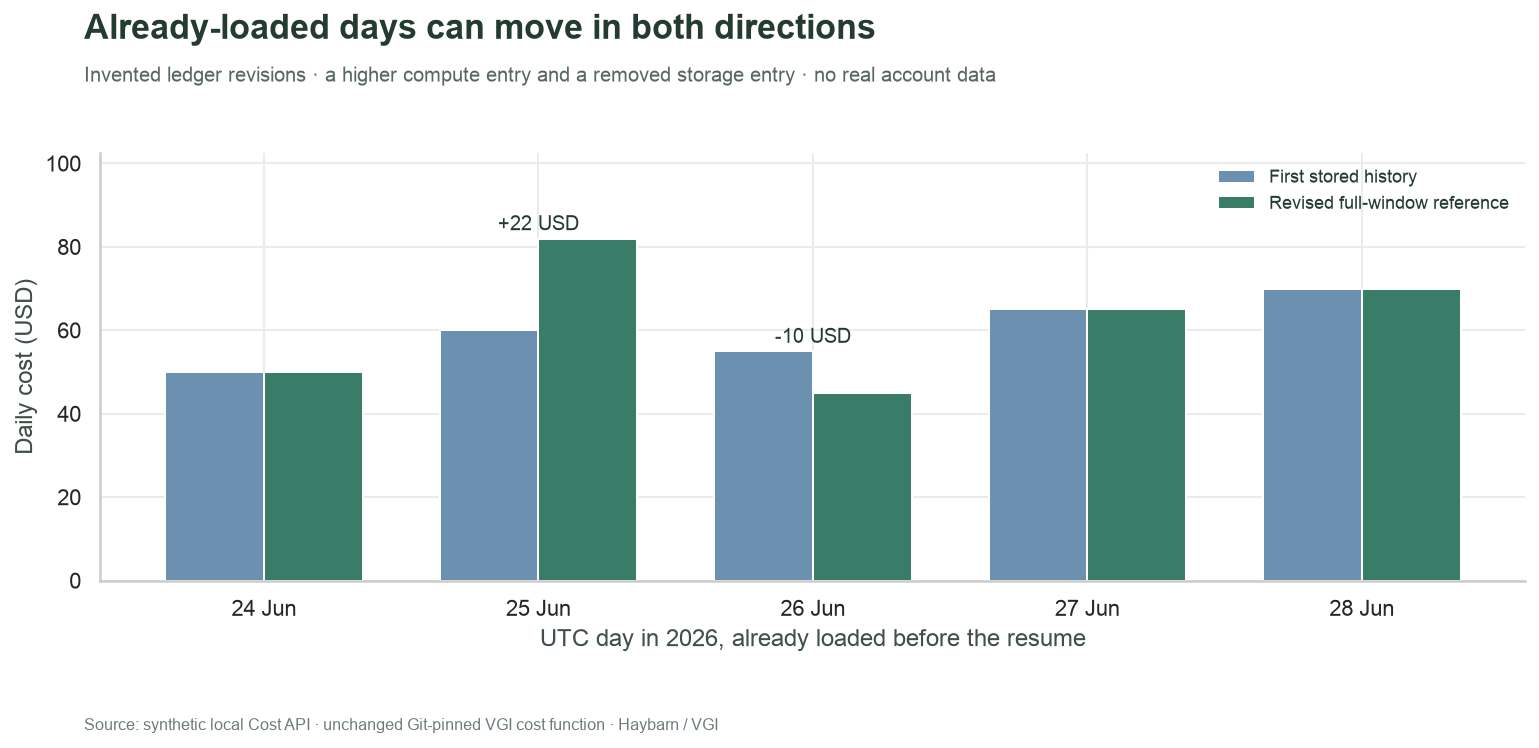

In [13]:
fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(revisions))
ax.bar(x - 0.18, revisions.first_usd, width=0.36, color="#6B90B0", label="First stored history")
ax.bar(x + 0.18, revisions.revised_usd, width=0.36, color="#397D68", label="Revised full-window reference")
ax.set_xticks(x, [pd.Timestamp(d).strftime("%d %b") for d in revisions.date])
ax.set_xlabel("UTC day in 2026, already loaded before the resume")
ax.set_ylabel("Daily cost (USD)")
ax.legend(fontsize=9)
ax.set_ylim(0, max(revisions.first_usd.max(), revisions.revised_usd.max()) * 1.25)
for i, row in revisions.iterrows():
    if abs(row.revision_usd) > 1e-9:
        ax.text(
            i,
            max(row.first_usd, row.revised_usd) + 2,
            f"{row.revision_usd:+.0f} USD",
            ha="center",
            fontsize=10,
        )
chart(
    fig,
    "Already-loaded days can move in both directions",
    "Invented ledger revisions · a higher compute entry and a removed storage entry · no real account data",
)

## Apply the returned window, then advance the watermark

Build two separate targets from the same first load. The append target adds all
new rows. The replacement target deletes every old row in the returned scope and
inclusive date window, inserts the replacement rows, and only then updates its
stored watermark. This also removes a key that disappeared from that window.

These visible statements demonstrate the sequence in an in-memory database. A
production sink must commit the data replacement and watermark atomically on one
transactional connection; this notebook does not simulate a crash between writes.

In [14]:
%%sql
CREATE TABLE appended AS SELECT * FROM original_ledger;
INSERT INTO appended
SELECT 'subscriptions/notebook-synthetic', date::DATE, "ResourceGroup", cost, currency
FROM second_batch WHERE _row_kind IS NULL;
CREATE TABLE replaced AS SELECT * FROM original_ledger;
DELETE FROM replaced
WHERE scope = 'subscriptions/notebook-synthetic'
  AND date BETWEEN
      (SELECT _restated_from::DATE FROM second_batch WHERE _row_kind = 'marker') AND
      (SELECT _watermark_next::DATE FROM second_batch WHERE _row_kind = 'marker');
INSERT INTO replaced
SELECT 'subscriptions/notebook-synthetic', date::DATE, "ResourceGroup", cost, currency
FROM second_batch WHERE _row_kind IS NULL;
UPDATE sync_state SET watermark_next =
    (SELECT _watermark_next FROM second_batch WHERE _row_kind = 'marker');
CREATE TABLE method_totals AS
SELECT 'Append both batches' AS method, sum(cost) AS usd, 1 AS position FROM appended
UNION ALL SELECT 'Replace returned window', sum(cost), 2 FROM replaced
UNION ALL SELECT 'Fresh full-window reference', sum(cost), 3 FROM fresh_reference;
SELECT method, usd FROM method_totals ORDER BY position;

,method,usd
0,Append both batches,767.0
1,Replace returned window,467.0
2,Fresh full-window reference,467.0


In [15]:
%%sql comparison <<
SELECT method, usd, usd - (SELECT sum(cost) FROM fresh_reference) AS error_usd
FROM method_totals ORDER BY position;

In [16]:
%%sql outcome <<
SELECT (SELECT _restated_from FROM second_batch WHERE _row_kind = 'marker') AS restated_from,
       (SELECT watermark_next FROM sync_state) AS next_watermark,
       (SELECT sum(cost) FROM appended) - (SELECT sum(cost) FROM fresh_reference) AS append_error_usd,
       (SELECT sum(cost) FROM replaced) - (SELECT sum(cost) FROM fresh_reference) AS replacement_error_usd,
       (SELECT count(*) FROM appended) -
          (SELECT count(*) FROM (SELECT DISTINCT scope, date, "ResourceGroup" FROM appended)) AS duplicate_keys;

In [17]:
r = outcome.iloc[0]
matched = abs(r.replacement_error_usd) < 1e-9
finding = (
    "The replacement target reconciles with the revised full-window reference."
    if matched
    else "The replacement target still differs from the reference: earlier revisions are outside its window."
)
prose(
    f"With **{LOOKBACK_DAYS} lookback days**, the returned window begins **{r.restated_from}** "
    f"and the stored watermark advances to **{r.next_watermark}**. Appending leaves "
    f"**{int(r.duplicate_keys)} duplicate keys** and a **USD {r.append_error_usd:+.2f}** total error. "
    f"Window replacement has **USD {r.replacement_error_usd:+.2f}** error. **{finding}**"
)

With **7 lookback days**, the returned window begins **2026-06-21** and the stored watermark advances to **2026-06-30**. Appending leaves **9 duplicate keys** and a **USD +300.00** total error. Window replacement has **USD +0.00** error. **The replacement target reconciles with the revised full-window reference.**

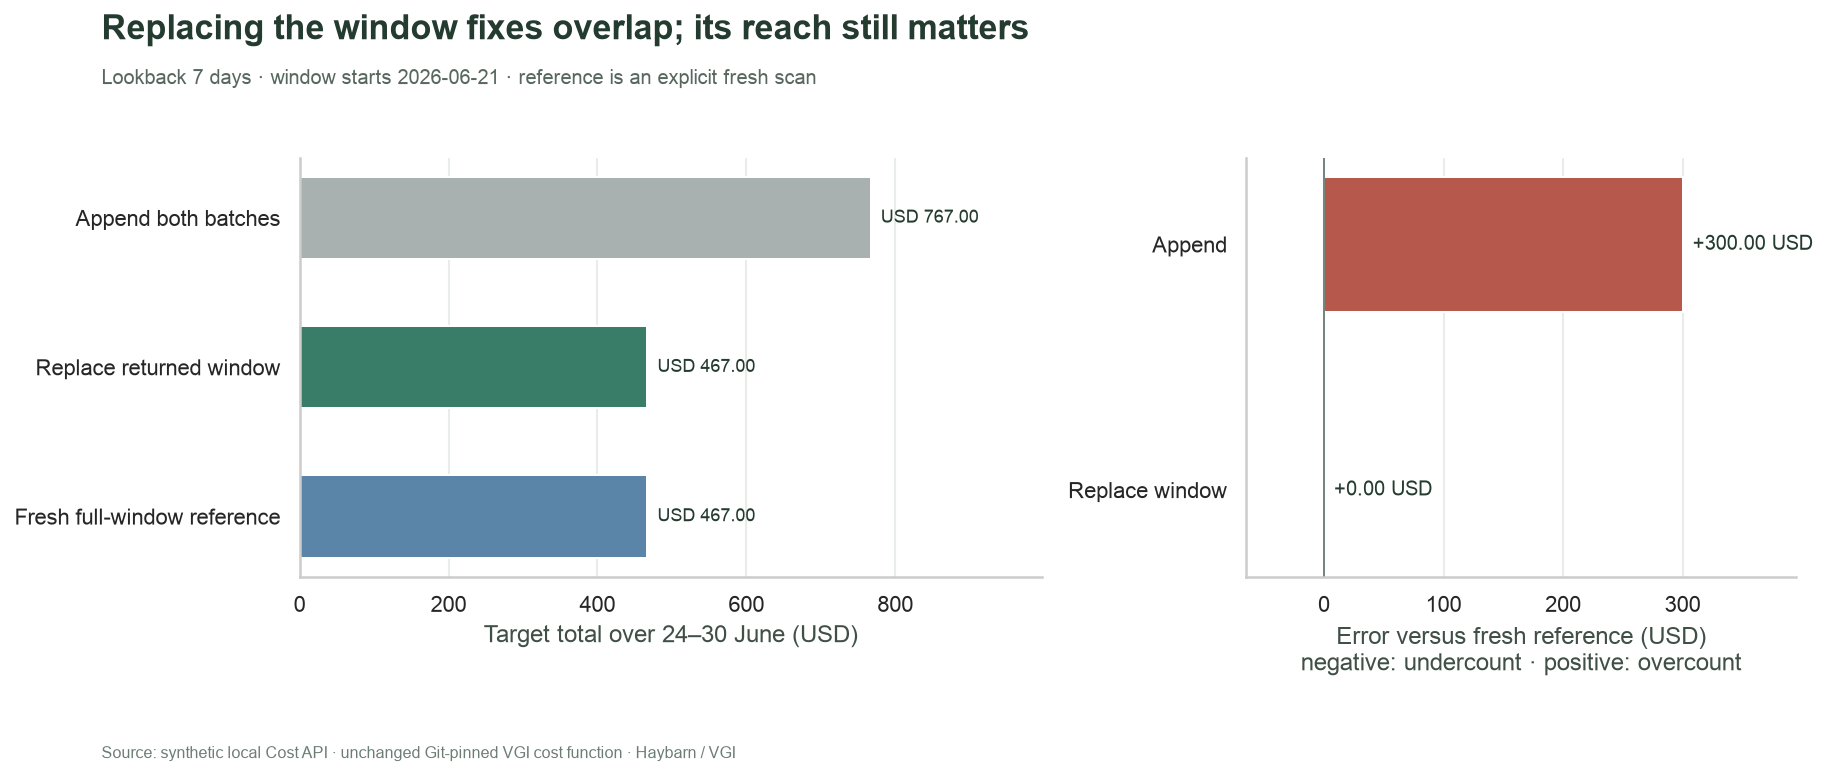

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.35, 1]})
bars = axes[0].barh(comparison.method, comparison.usd, color=["#A8B1B0", "#397D68", "#5A85A8"], height=0.55)
axes[0].bar_label(bars, labels=[f"USD {v:,.2f}" for v in comparison.usd], padding=5, fontsize=9)
axes[0].set_xlim(0, comparison.usd.max() * 1.3)
axes[0].set_xlabel("Target total over 24–30 June (USD)")
errors = comparison.iloc[:2]
error_colors = ["#B6594C" if v > 1e-9 else "#BE8738" if v < -1e-9 else "#397D68" for v in errors.error_usd]
bars = axes[1].barh(["Append", "Replace window"], errors.error_usd, color=error_colors, height=0.55)
axes[1].bar_label(bars, labels=[f"{v:+.2f} USD" for v in errors.error_usd], padding=5, fontsize=10)
axes[1].axvline(0, color="#75867C", linewidth=1)
axes[1].set_xlim(min(0, errors.error_usd.min()) - 65, max(0, errors.error_usd.max()) + 95)
axes[1].set_xlabel("Error versus fresh reference (USD)\nnegative: undercount · positive: overcount")
for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
chart(
    fig,
    "Replacing the window fixes overlap; its reach still matters",
    f"Lookback {LOOKBACK_DAYS} days · window starts {r.restated_from} · reference is an explicit fresh scan",
)

## Check delivery and application relationships

The source costs are Float64, so comparisons use a small numerical tolerance.
The checks verify marker shape, currency, target uniqueness, complete replacement
inside the returned window, and the stored watermark. They deliberately do not
require equality to the full-window reference: the zero-day experiment should
expose a stale history while still correctly applying the smaller window.

In [19]:
%%sql checks <<
SELECT 'one marker in each resumed batch' AS check_name,
       (SELECT count(*) FROM first_batch WHERE _row_kind = 'marker') = 1 AND
       (SELECT count(*) FROM second_batch WHERE _row_kind = 'marker') = 1 AS passed
UNION ALL SELECT 'marker contains no business values', bool_and(
       date IS NULL AND "ResourceGroup" IS NULL AND cost IS NULL AND currency IS NULL)
       FROM second_batch WHERE _row_kind = 'marker'
UNION ALL SELECT 'required business values and USD', bool_and(
       date IS NOT NULL AND "ResourceGroup" IS NOT NULL AND cost IS NOT NULL AND currency = 'USD')
       FROM second_batch WHERE _row_kind IS NULL
UNION ALL SELECT 'replacement key stays unique', count(*) = count(DISTINCT (scope,date,"ResourceGroup")) FROM replaced
UNION ALL SELECT 'replacement window equals returned rows', NOT EXISTS (
       (SELECT date, "ResourceGroup", cost, currency FROM replaced
        WHERE date BETWEEN (SELECT _restated_from::DATE FROM second_batch WHERE _row_kind = 'marker')
                       AND (SELECT _watermark_next::DATE FROM second_batch WHERE _row_kind = 'marker')
        EXCEPT SELECT date::DATE, "ResourceGroup", cost, currency FROM second_batch WHERE _row_kind IS NULL)
       UNION ALL
       (SELECT date::DATE, "ResourceGroup", cost, currency FROM second_batch WHERE _row_kind IS NULL
        EXCEPT SELECT date, "ResourceGroup", cost, currency FROM replaced))
UNION ALL SELECT 'append total is the sum of two loads', abs(
       (SELECT sum(cost) FROM appended) - (SELECT sum(cost) FROM original_ledger) -
       (SELECT sum(cost) FROM second_batch WHERE _row_kind IS NULL)) < 1e-9
UNION ALL SELECT 'watermark advanced after replacement',
       (SELECT watermark_next FROM sync_state) =
       (SELECT _watermark_next FROM second_batch WHERE _row_kind = 'marker');

In [20]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "A delivery/application relationship failed"
# Audit the transport trace: continuation requests retain the identical original body.
import json

bodies = {}
for request in fixture.requests:
    key = (request["phase"], request["body"]["timePeriod"]["from"], request["body"]["timePeriod"]["to"])
    serialized = json.dumps(request["body"], sort_keys=True)
    assert key not in bodies or bodies[key] == serialized
    bodies[key] = serialized
prose(
    f"**All {len(checks)} SQL relationships passed.** The worker made "
    f"**{len(fixture.requests)} local HTTP POSTs** across three materialized scans. "
    "Continuation requests retained their original bodies. All endpoint responses were synthetic."
)

,check_name,passed
0,one marker in each resumed batch,True
1,marker contains no business values,True
2,required business values and USD,True
3,replacement key stays unique,True
4,replacement window equals returned rows,True
5,append total is the sum of two loads,True
6,watermark advanced after replacement,True


**All 7 SQL relationships passed.** The worker made **14 local HTTP POSTs** across three materialized scans. Continuation requests retained their original bodies. All endpoint responses were synthetic.

## Experiment: remove the historical lookback

Change **`LOOKBACK_DAYS = 7` to `LOOKBACK_DAYS = 0`**, restart, and run all. Predict
that replacement still avoids duplicate keys, but misses changes before the prior
watermark. Compare the returned lower bound, the second figure's replacement
error, and the statement beneath the totals. The application checks should pass
in both runs because applying a short window correctly does not repair older data.

Zero lookback still includes the watermark day; it is not a non-overlapping append
policy. A seven-day buffer catches this fixture's revisions but cannot guarantee
that every real late adjustment is covered. Restore **7** for the default; the
[guide](README.md) gives the separate experiment command.

In [21]:
con.close()
cleanup(fixture, previous_url)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)